# Phase 2 : Notebook 2

In this notebook I will follow the corrected pipeline from my Flowchart 3. I check the data, remove redundant features, apply scaling and use a stratified 80/20 train-test split. I also try different hyperparameters and use macro F1 as the main metric. And stress test the models to see how well they perform.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

In [2]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('faults.csv')

class_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
df['Defect_Type'] = df[class_cols].idxmax(axis=1)

feature_cols = [c for c in df.columns if c not in class_cols + ['Defect_Type']]
X = df[feature_cols]
y = df['Defect_Type']
print(X.shape)

Saving faults.csv to faults.csv
(1941, 27)


In [3]:
# checking missing values and duplicate rows
print("missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print(X.dtypes.value_counts())

missing values: 0
duplicate rows: 0
int64      14
float64    13
Name: count, dtype: int64


I use the IQR rule to identify outliers. A value is considered an outlier if it falls below or above these limits:

$$x < Q_1 - 1.5 \cdot IQR \quad \text{or} \quad x > Q_3 + 1.5 \cdot IQR, \qquad IQR = Q_3 - Q_1$$

I keep the outliers because they could represent real defects rather than errors in the data.

In [4]:
outlier_counts = {}
for col in feature_cols:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outlier_counts[col] = ((X[col] < low) | (X[col] > high)).sum()

outlier_series = pd.Series(outlier_counts).sort_values(ascending=False)
print(outlier_series.head(10))


Sum_of_Luminosity        399
Pixels_Areas             395
Outside_X_Index          370
X_Perimeter              352
Steel_Plate_Thickness    240
Y_Perimeter              179
Maximum_of_Luminosity    146
Luminosity_Index         134
Y_Minimum                 81
Y_Maximum                 81
dtype: int64


I mark feature pairs as redundant if their absolute Pearson correlation is above 0.95. Pearson correlation measures how strongly two features are related.

$$r = \frac{\text{cov}(X, Y)}{\sigma_X \, \sigma_Y}$$

In [5]:
corr = X.corr().abs()
high_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if corr.iloc[i, j] > 0.95:
            high_pairs.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))

for pair in high_pairs:
    print(pair)

('X_Minimum', 'X_Maximum', np.float64(0.988))
('Y_Minimum', 'Y_Maximum', np.float64(1.0))
('Pixels_Areas', 'X_Perimeter', np.float64(0.967))
('Pixels_Areas', 'Sum_of_Luminosity', np.float64(0.979))
('TypeOfSteel_A300', 'TypeOfSteel_A400', np.float64(1.0))


Five feature pairs have a correlation above 0.95. I drop TypeOfSteel_A400 because it is the exact opposite of A300 along with Y_Maximum and X_Maximum. I keep Pixels_Areas, Sum_of_Luminosity and X_Perimeter because they measure different things like size, brightness and shape.

In [6]:
drop_cols = ['TypeOfSteel_A400', 'Y_Maximum', 'X_Maximum']
X_reduced = X.drop(columns=drop_cols)
print(X_reduced.shape)

(1941, 24)


I use a stratified 80/20 train-test split to keep the class proportions similar in both sets. The scaler is fitted on the training data only to avoid data leakage.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42, stratify=y)

print(y_train.value_counts())
print(y_test.value_counts())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Defect_Type
Other_Faults    538
Bumps           321
K_Scatch        313
Z_Scratch       152
Pastry          126
Stains           58
Dirtiness        44
Name: count, dtype: int64
Defect_Type
Other_Faults    135
Bumps            81
K_Scatch         78
Z_Scratch        38
Pastry           32
Stains           14
Dirtiness        11
Name: count, dtype: int64


In [8]:
def make_models():
    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'SVM': SVC(random_state=42),
        'Random Forest': RandomForestClassifier(random_state=42)
    }
    return models

rows = []
for name, model in make_models().items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred) * 100
    mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
    rows.append([name, acc, mp, mr, mf, wf])

default_df = pd.DataFrame(rows, columns=['Model', 'Accuracy (%)', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1']).round(2)
default_df

,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,72.49,0.76,0.73,0.74,0.72
1,Decision Tree,74.29,0.73,0.73,0.73,0.74
2,SVM,75.84,0.81,0.75,0.77,0.76
3,Random Forest,79.69,0.83,0.79,0.81,0.80


With the default settings and scaling Random Forest performs best with 79.69% accuracy and a macro F1 of 0.81. SVM comes next followed by Decision Tree and Logistic Regression.

In [9]:
feature_sets = {'all 27 features': X, 'reduced 24 features': X_reduced}
ablation = {}

for set_name in feature_sets:
    for name in make_models():
        ablation[(set_name, name)] = []

for seed in range(10):
    for set_name, data in feature_sets.items():
        Xtr, Xte, ytr, yte = train_test_split(data, y, test_size=0.2, random_state=seed, stratify=y)
        sc = StandardScaler()
        Xtr_s = sc.fit_transform(Xtr)
        Xte_s = sc.transform(Xte)
        for name, model in make_models().items():
            model.fit(Xtr_s, ytr)
            pred = model.predict(Xte_s)
            ablation[(set_name, name)].append(accuracy_score(yte, pred) * 100)

ablation_rows = []
for (set_name, name), values in ablation.items():
    ablation_rows.append([set_name, name, np.mean(values), np.std(values)])

ablation_df = pd.DataFrame(ablation_rows, columns=['Feature set', 'Model', 'Mean accuracy (%)', 'Std'])
ablation_df.round(2)

,Feature set,Model,Mean accuracy (%),Std
0,all 27 features,Logistic Regression,71.75,1.36
1,all 27 features,Decision Tree,70.85,3.03
2,all 27 features,SVM,75.68,1.96
3,all 27 features,Random Forest,78.35,2.80
4,reduced 24 features,Logistic Regression,71.80,1.29
5,reduced 24 features,Decision Tree,71.67,3.05
6,reduced 24 features,SVM,75.01,2.07
7,reduced 24 features,Random Forest,77.46,1.96


Dropping the three features changes accuracy by less than 1 percentage point for every model which is smaller than the variation between splits so removing these features does not make much difference to the results.

In [10]:
# looking at every class separately mainly Dirtiness and Stains
for name, model in make_models().items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    print("=====", name, "=====")
    print(classification_report(y_test, y_pred, zero_division=0))

===== Logistic Regression =====
              precision    recall  f1-score   support

       Bumps       0.69      0.57      0.62        81
   Dirtiness       0.88      0.64      0.74        11
    K_Scatch       0.93      0.91      0.92        78
Other_Faults       0.64      0.71      0.67       135
      Pastry       0.50      0.53      0.52        32
      Stains       0.86      0.86      0.86        14
   Z_Scratch       0.82      0.87      0.85        38

    accuracy                           0.72       389
   macro avg       0.76      0.73      0.74       389
weighted avg       0.73      0.72      0.72       389

===== Decision Tree =====
              precision    recall  f1-score   support

       Bumps       0.70      0.69      0.70        81
   Dirtiness       0.73      0.73      0.73        11
    K_Scatch       0.97      0.86      0.91        78
Other_Faults       0.68      0.74      0.71       135
      Pastry       0.46      0.34      0.39        32
      Stains       0

Pastry is the hardest class to predict for all four models. Dirtiness and Stains are detected fairly well but they only have 11 and 14 test samples so the results should be taken with some caution.

I try different hyperparameter combinations using 5-fold cross-validation on the training data only. The score is the average macro F1 across the five folds:

$$\text{CV score} = \frac{1}{5}\sum_{k=1}^{5} \text{Macro F1}_k$$

The scaler is included in a pipeline so each fold is scaled using only its own training data. The test set is kept separate and used only for the final evaluation.

Settings I try:
- Logistic Regression: $C$ and `class_weight`
- Decision Tree: `max_depth`, `min_samples_leaf` and `criterion` (Gini $= 1 - \sum_i p_i^2$ or entropy $= -\sum_i p_i \log_2 p_i$)
- SVM: `kernel`, $C$ and $\gamma$ (scale $= \frac{1}{n_{features} \cdot Var(X)}$, auto $= \frac{1}{n_{features}}$)
- Random Forest: number of trees, `max_depth` and `min_samples_leaf`

In [11]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


grids = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.01, 0.1, 1, 10, 100],
         'model__class_weight': [None, 'balanced']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 10, 15, None],
         'model__criterion': ['gini', 'entropy'],
         'model__min_samples_leaf': [1, 5]}),
    'SVM': (SVC(random_state=42),
        {'model__kernel': ['linear', 'rbf', 'poly'],
         'model__C': [0.1, 1, 10, 100],
         'model__gamma': ['scale', 'auto']}),
    'Random Forest': (RandomForestClassifier(random_state=42),
        {'model__n_estimators': [50, 100, 200, 300],
         'model__max_depth': [None, 10, 20],
         'model__min_samples_leaf': [1, 2, 5]})
}

best_models = {}
all_cv = {}

for name, (model, params) in grids.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
    search = GridSearchCV(pipe, params, cv=cv, scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search
    all_cv[name] = pd.DataFrame(search.cv_results_)
    print(name, "| best cv macro F1:", round(search.best_score_, 3))
    print("   best params:", search.best_params_)

Logistic Regression | best cv macro F1: 0.722
   best params: {'model__C': 100, 'model__class_weight': None}
Decision Tree | best cv macro F1: 0.757
   best params: {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 1}
SVM | best cv macro F1: 0.776
   best params: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Random Forest | best cv macro F1: 0.782
   best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


In [12]:
for name, res in all_cv.items():
    print("=====", name, "=====")
    top = res[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
    top = top.sort_values('rank_test_score').head(5)
    print(top.round(3).to_string(index=False))

===== Logistic Regression =====
                                             params  mean_test_score  std_test_score  rank_test_score
     {'model__C': 100, 'model__class_weight': None}            0.722           0.019                1
       {'model__C': 1, 'model__class_weight': None}            0.721           0.025                2
      {'model__C': 10, 'model__class_weight': None}            0.714           0.030                3
     {'model__C': 0.1, 'model__class_weight': None}            0.687           0.026                4
{'model__C': 10, 'model__class_weight': 'balanced'}            0.672           0.013                5
===== Decision Tree =====
                                                                                 params  mean_test_score  std_test_score  rank_test_score
  {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 1}            0.757           0.014                1
{'model__criterion': 'entropy', 'model__max_depth': No

The best settings were C=100 for Logistic Regression, entropy with a depth of 10 for Decision Tree, RBF with C=10 for SVM and 200 trees for Random Forest. Many of the other combinations scored almost the same.

In [13]:
final_rows = []
for name, search in best_models.items():
    y_pred = search.predict(X_test)
    acc = accuracy_score(y_test, y_pred) * 100
    mp, mr, mf, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    final_rows.append([name, acc, mf])

final_df = pd.DataFrame(final_rows, columns=['Model', 'Tuned Accuracy (%)', 'Tuned Macro F1'])
final_df['Default Accuracy (%)'] = default_df['Accuracy (%)'].values
final_df['Default Macro F1'] = default_df['Macro F1'].values
final_df.round(2)

,Model,Tuned Accuracy (%),Tuned Macro F1,Default Accuracy (%),Default Macro F1
0,Logistic Regression,74.04,0.74,72.49,0.74
1,Decision Tree,74.04,0.76,74.29,0.73
2,SVM,76.09,0.78,75.84,0.77
3,Random Forest,79.95,0.81,79.69,0.81


The tuned and default results are very close with differences of 1.6 percentage points or less. So tuning did not make much difference.

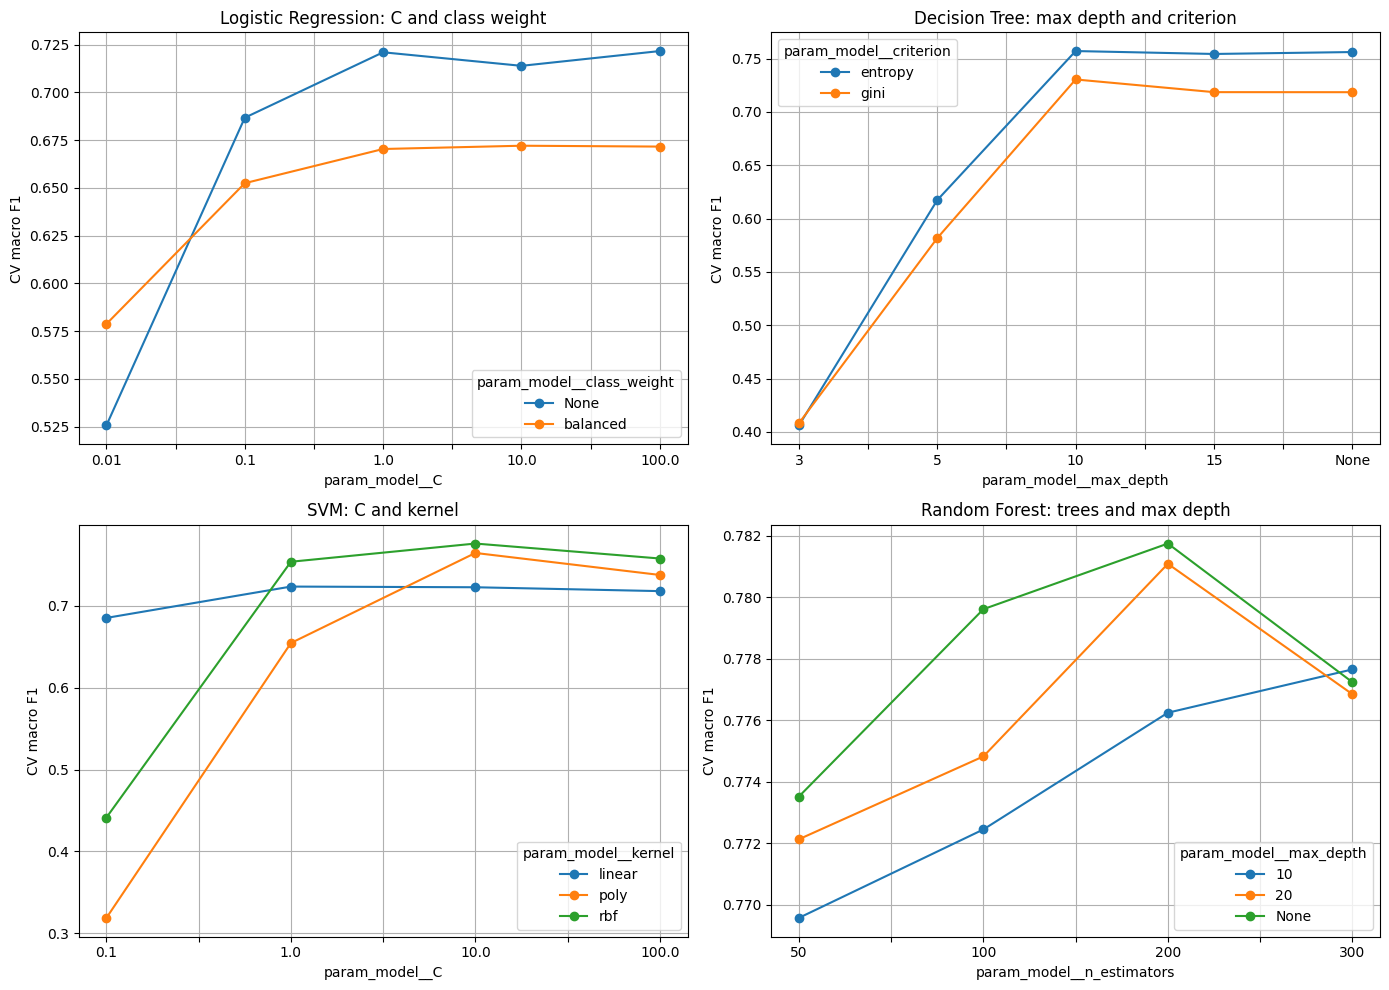

In [14]:
# plotting the cv scores for the values i tried for each point i take the best score over the other settings
def plot_grid(ax, res, x_col, line_col, x_order, title):
    tmp = res.copy()
    tmp[x_col] = tmp[x_col].astype(str)
    tmp[line_col] = tmp[line_col].astype(str)
    table = tmp.groupby([x_col, line_col])['mean_test_score'].max().unstack()
    table = table.reindex(x_order)
    table.plot(marker='o', ax=ax)
    ax.set_title(title)
    ax.set_ylabel('CV macro F1')
    ax.grid(True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_grid(axes[0, 0], all_cv['Logistic Regression'], 'param_model__C', 'param_model__class_weight',
          ['0.01', '0.1', '1.0', '10.0', '100.0'], 'Logistic Regression: C and class weight')
plot_grid(axes[0, 1], all_cv['Decision Tree'], 'param_model__max_depth', 'param_model__criterion',
          ['3', '5', '10', '15', 'None'], 'Decision Tree: max depth and criterion')
plot_grid(axes[1, 0], all_cv['SVM'], 'param_model__C', 'param_model__kernel',
          ['0.1', '1.0', '10.0', '100.0'], 'SVM: C and kernel')
plot_grid(axes[1, 1], all_cv['Random Forest'], 'param_model__n_estimators', 'param_model__max_depth',
          ['50', '100', '200', '300'], 'Random Forest: trees and max depth')

plt.tight_layout()
plt.show()

In [15]:
# numbers copied from my earlier outputs (paper tables and my two notebooks)
# note: replication test set = 180 samples and corrected pipeline test set = 389 samples
models_list = ['Logistic Regression', 'Decision Tree', 'SVM', 'Random Forest']

comparison = pd.DataFrame({
    'Model': models_list,
    'Paper Acc (%)':                [74.44, 77.77, 74.44, 79.44],
    'Replication unscaled Acc (%)': [46.11, 73.89, 48.89, 78.33],
    'Replication scaled Acc (%)':   [72.22, 73.89, 77.22, 77.78],
    'Corrected default Acc (%)':    [72.49, 74.29, 75.84, 79.69],
    'Corrected tuned Acc (%)':      [74.04, 74.04, 76.09, 79.95],
})
print(comparison.to_string(index=False))

f1_comparison = pd.DataFrame({
    'Model': models_list,
    'Paper Macro F1':                [0.77, 0.75, 0.77, 0.82],
    'Replication unscaled Macro F1': [0.24, 0.77, 0.24, 0.79],
    'Replication scaled Macro F1':   [0.70, 0.77, 0.78, 0.79],
    'Corrected default Macro F1':    [0.74, 0.73, 0.77, 0.81],
    'Corrected tuned Macro F1':      [0.74, 0.76, 0.78, 0.81],
})
print(f1_comparison.to_string(index=False))

              Model  Paper Acc (%)  Replication unscaled Acc (%)  Replication scaled Acc (%)  Corrected default Acc (%)  Corrected tuned Acc (%)
Logistic Regression          74.44                         46.11                       72.22                      72.49                    74.04
      Decision Tree          77.77                         73.89                       73.89                      74.29                    74.04
                SVM          74.44                         48.89                       77.22                      75.84                    76.09
      Random Forest          79.44                         78.33                       77.78                      79.69                    79.95
              Model  Paper Macro F1  Replication unscaled Macro F1  Replication scaled Macro F1  Corrected default Macro F1  Corrected tuned Macro F1
Logistic Regression            0.77                           0.24                         0.70                        0.74  

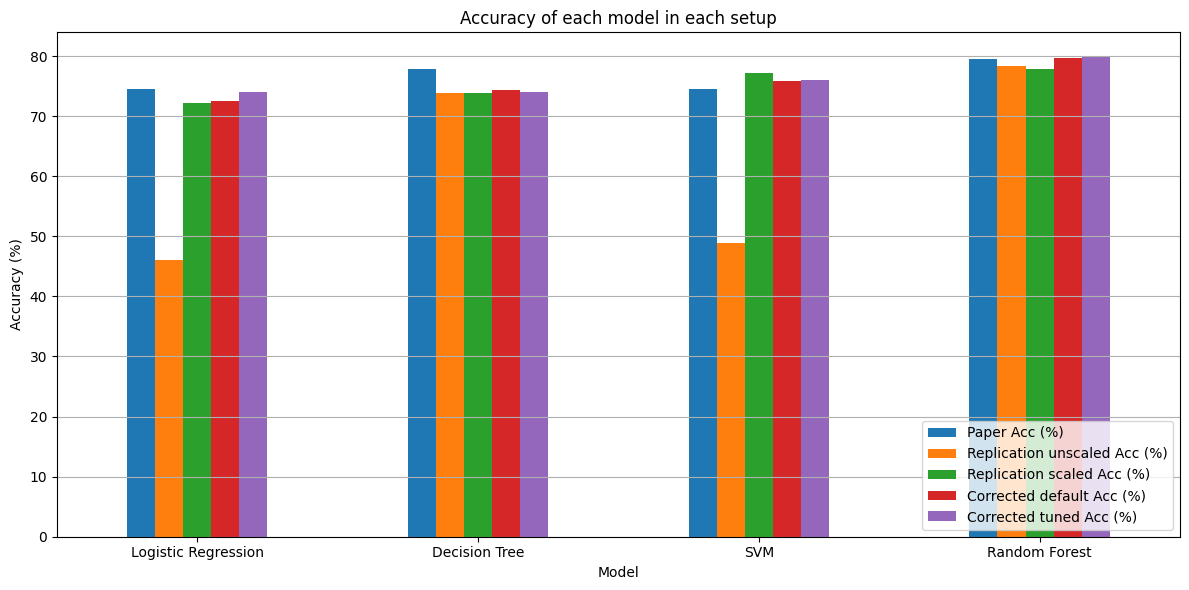

In [16]:
comparison.set_index('Model').plot(kind='bar', figsize=(12, 6))
plt.ylabel('Accuracy (%)')
plt.title('Accuracy of each model in each setup')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

I compare everything side by side. The replication test set has 180 samples, while the corrected pipeline test set has 389 so I focus on the overall trends rather than the exact numbers.

## Stress Testing
My hypothesis before running the tests is that noise will reduce the accuracy of every model. I also expect extra useless features to affect SVM and Logistic Regression the most while Random Forest should handle them better.

Test 1: I add noise to the scaled test features using $x' = x + \epsilon$ where $\epsilon \sim N(0, \sigma^2)$.

Test 2: I add columns of random numbers to the training and test data then train the models again.

Always predicting the largest class Other_Faults gives an accuracy of $135/389 = 34.7\%$.

In [17]:
# the best settings found by grid search
def tuned_models():
    models = {
        'Logistic Regression': LogisticRegression(C=100, max_iter=2000, random_state=42),
        'Decision Tree': DecisionTreeClassifier(criterion='entropy', max_depth=10, random_state=42),
        'SVM': SVC(kernel='rbf', C=10, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42)
    }
    return models

I train the models on clean data then add random noise to the test features. Since the data is already scaled sigma is measured in standard deviation units. I also add noise to the 0/1 steel type column to keep things simple.

In [18]:
rng = np.random.RandomState(42)

fitted = tuned_models()
for name, model in fitted.items():
    model.fit(X_train_scaled, y_train)

noise_levels = [0, 0.25, 0.5, 1.0, 2.0]
noise_rows = []

for sigma in noise_levels:
    scores = {name: [] for name in fitted}
    for rep in range(5):
        X_noisy = X_test_scaled + rng.normal(0, sigma, X_test_scaled.shape)
        for name, model in fitted.items():
            scores[name].append(accuracy_score(y_test, model.predict(X_noisy)) * 100)
    row = {'noise sigma': sigma}
    for name in fitted:
        row[name] = np.mean(scores[name])
    noise_rows.append(row)

noise_df = pd.DataFrame(noise_rows).round(2)
print(noise_df.to_string(index=False))

 noise sigma  Logistic Regression  Decision Tree   SVM  Random Forest
        0.00                74.04          74.04 76.09          79.95
        0.25                46.68          52.39 76.09          63.50
        0.50                36.14          41.29 68.64          54.40
        1.00                28.33          33.52 46.89          44.01
        2.00                22.67          27.61 34.76          36.76


Accuracy drops quickly for all models but SVM handles small amounts of noise the best.

I add random columns that have no relation to the defect type and retrain the models each time with the extra features.

In [19]:
extra_counts = [0, 25, 100, 300]
dim_rows = []

for k in extra_counts:
    extra_train = rng.normal(0, 1, (X_train_scaled.shape[0], k))
    extra_test = rng.normal(0, 1, (X_test_scaled.shape[0], k))
    Xtr = np.hstack([X_train_scaled, extra_train])
    Xte = np.hstack([X_test_scaled, extra_test])

    row = {'extra random features': k}
    for name, model in tuned_models().items():
        model.fit(Xtr, y_train)
        row[name] = accuracy_score(y_test, model.predict(Xte)) * 100
    dim_rows.append(row)

dim_df = pd.DataFrame(dim_rows).round(2)
print(dim_df.to_string(index=False))

 extra random features  Logistic Regression  Decision Tree   SVM  Random Forest
                     0                74.04          74.04 76.09          79.95
                    25                68.38          71.72 67.10          76.35
                   100                59.13          70.44 64.52          72.49
                   300                51.16          66.58 53.73          65.81


SVM and Logistic Regression are affected the most by the extra features. Decision Tree handles them best so my hypothesis about Random Forest was only partly correct.

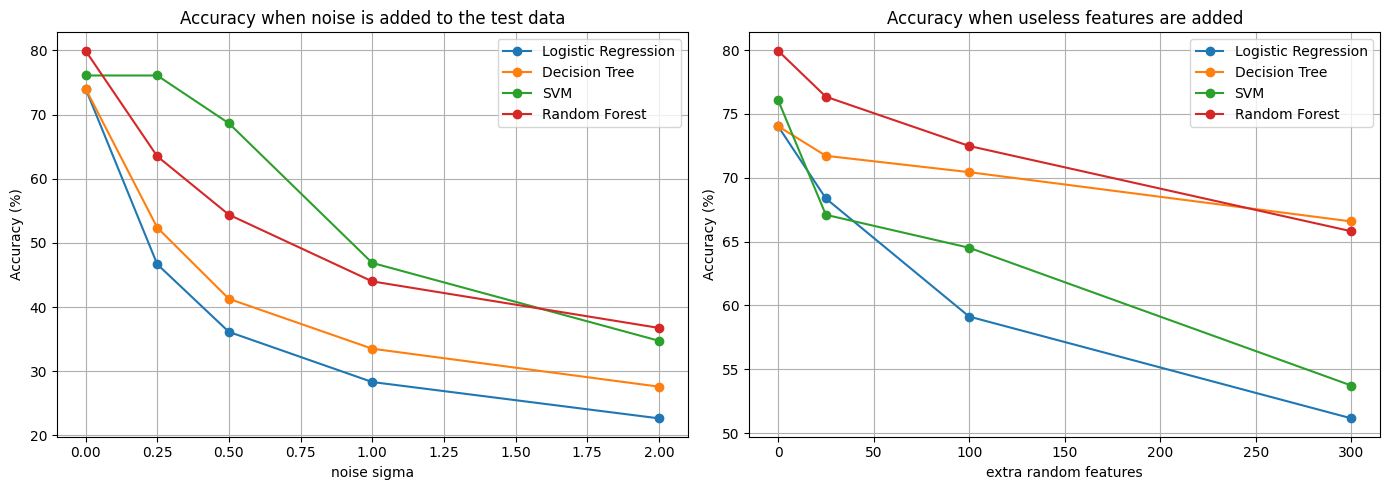

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

noise_df.set_index('noise sigma').plot(marker='o', ax=axes[0])
axes[0].set_title('Accuracy when noise is added to the test data')
axes[0].set_ylabel('Accuracy (%)')
axes[0].grid(True)

dim_df.set_index('extra random features').plot(marker='o', ax=axes[1])
axes[1].set_title('Accuracy when useless features are added')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Corrected Implementation and Further Evaluation

After the initial replication I made some changes to the experimental pipeline to fix the limitations I found earlier. The dataset contains 1,941 samples with 27 original features and seven defect classes. During the data quality checks I found no missing values or duplicate rows. I kept the outliers identified using IQR because they could represent actual steel defects rather than errors in the data. I also checked the feature correlations and removed three highly correlated features: TypeOfSteel_A400, Y_Maximum and X_Maximum. This reduced the number of features from 27 to 24.

I used a stratified 80/20 train-test split with 1,552 training samples and 389 test samples using random_state=42. This helped maintain the representation of minority classes. Dirtiness had 11 test samples and Stains had 14. I used StandardScaler to scale the features and fitted it only on the training data to prevent data leakage.

I evaluated the baseline scaled models and used 5-fold stratified cross-validation. I also performed hyperparameter tuning using GridSearchCV. The results are shown below.

| Model | Baseline Accuracy | Baseline Macro F1 | CV Macro F1 | Tuned Test Accuracy | Tuned Macro F1 |
|---|---|---|---|---|---|
| Logistic Regression | — | — | 0.722 | — | — |
| Decision Tree | — | — | 0.757 | — | — |
| SVM | 75.84% | 0.77 | 0.776 | — | — |
| Random Forest | 79.69% | 0.81 | 0.782 | 79.95% | 0.81 |

The results show that hyperparameter tuning only gave small improvements in performance. This suggests that the main improvements came from correcting the pipeline through stratification and feature selection and applying scaling correctly. Pastry was the most difficult defect class to classify correctly across the evaluations.

I compared the results from the different experimental setups to see how the models performed under different conditions.

| Setup | Test Split Size | Random Forest Accuracy |
|---|---|---|
| Original Paper | Unclear (Stated 95/5. Matrices show 180 samples) | 79.44% |
| Notebook 1 (Unscaled) | Fixed 180 samples | 78.33% |
| Notebook 1 (Scaled) | Fixed 180 samples | 77.78% |
| Notebook 2 (Corrected & Scaled) | Stratified 389 samples (80/20) | 79.69% (Default) / 79.95% (Tuned) |

A direct statistical comparison between Notebook 1 and Notebook 2 is not valid because they use different test sample sizes and split strategies. I also could not reproduce the original paper exactly because the original preprocessing settings were not clearly explained.

I tested the tuned models under less ideal conditions to understand how they handled noise and irrelevant features.

- **Random Gaussian Noise:** Model accuracy decreased across all architectures as the noise increased. SVM performed better at lower noise levels but its performance declined as the noise increased.

- **Irrelevant Synthetic Features:** Adding random features with no useful information caused a major drop in Logistic Regression and SVM performance. Decision Tree handled these extra features the best. Random Forest also showed a moderate drop in accuracy. This showed that tree-based ensemble models are not completely immune to irrelevant features.

The results show that Random Forest achieved the highest test accuracy of 79.95% on the steel plate fault dataset after tuning. The improvement over the default model was small. This suggests that hyperparameter tuning alone did not make a major difference. The stress tests also showed that noise and irrelevant features can affect model performance. Therefore it is important to consider how models perform on both clean data and data that contains noise or irrelevant features when applying them in real-world situations.